# Exploration des données horaires Météo-France — Paris (75)

Objectif : comprendre les fichiers, les stations, les colonnes, leurs unités et leur disponibilité avant toute jointure avec les données de pollution.

Ce notebook lit les trois archives locales sans les modifier. Aucun remplacement des valeurs manquantes, filtrage qualité ou dédoublonnage automatique. Les fonctions réutilisables sont dans `src/air_quality_prediction/meteofrance.py`.

Sources Météo-France consultées le 27 novembre 2026 :
- [Jeu de données horaires](https://www.data.gouv.fr/datasets/donnees-climatologiques-de-base-horaires) : heures UTC pour la métropole.
- [Dictionnaire des champs](https://meteofrance.s3.sbg.io.cloud.ovh.net/data/synchro_ftp/BASE/HOR/H_descriptif_champs.csv), dont une copie locale est conservée dans `data/reference/meteofrance/`.
- [Descriptif officiel PDF du 3 juin 2026](https://static.data.gouv.fr/resources/donnees-climatologiques-de-base-horaires/20260603-085646/climatologie-donnees-horaires-descriptif-20260603.pdf) : unités et codes qualité.

Source des données : Météo-France, Licence Ouverte 2.0. Les textes du dictionnaire sont des métadonnées descriptives.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Fonctionne depuis la racine du dépôt ou notebooks/eda.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/air_quality_prediction").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Lancer le notebook depuis le dépôt du projet.")
sys.path.insert(0, str(ROOT / "src"))
from air_quality_prediction.meteofrance import (
    read_hourly_files, read_descriptions, column_profile,
    station_coverage, QUALITY_LABELS,
)
pd.set_option("display.max_colwidth", 110)
sns.set_theme(style="whitegrid")


## 1. Chargement et inventaire

CSV séparés par `;`, compressés en gzip, décimales avec un point. `NUM_POSTE` est un identifiant, conservé en texte. `AAAAMMJJHH` est une date au format année/mois/jour/heure ; `date_utc` est sa version analysable. Les colonnes ajoutées sont `date_utc` et `fichier_source`.

Le chargement complet peut consommer quelques Go de RAM. Le nombre de lignes est calculé sur les fichiers, pas déduit de leur nom.


In [2]:
FILES = [ROOT / "data/raw/datagouv" / name for name in [
    "H_75_2010-2019.csv.gz",
    "H_75_previous-2020-2024.csv.gz",
    "H_75_latest-2025-2026.csv.gz",
]]
meteo, inventory = read_hourly_files(FILES)
display(inventory.drop(columns="schema"))
print("Schémas identiques :", inventory["schema"].nunique() == 1)
print(f"{len(meteo):,} lignes ; {meteo.NUM_POSTE.nunique()} stations")
print("Période UTC :", meteo.date_utc.min(), "→", meteo.date_utc.max())
print(f"Mémoire DataFrame : {meteo.memory_usage(deep=True).sum() / 1e9:.2f} Go")
display(meteo.head())


,fichier,lignes,colonnes,taille_Mo
0,H_75_2010-2019.csv.gz,350633,206,14.837087
1,H_75_latest-2025-2026.csv.gz,100069,206,3.478417
2,H_75_previous-2020-2024.csv.gz,261860,206,9.084848


Schémas identiques : True
712,562 lignes ; 17 stations
Période UTC : 2010-01-01 00:00:00+00:00 → 2026-11-27 04:00:00+00:00
Mémoire DataFrame : 1.23 Go


,NUM_POSTE,NOM_USUEL,LAT,LON,ALTI,AAAAMMJJHH,RR1,QRR1,DRR1,QDRR1,...,TLAGON,QTLAGON,TVEGETAUX,QTVEGETAUX,ECOULEMENT,QECOULEMENT,STATUS_FXI3S,STATUS_DXI3S,date_utc,fichier_source
0,75106001,LUXEMBOURG,48.844833,2.3385,50,2013011906,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013-01-19 06:00:00+00:00,H_75_2010-2019.csv.gz
1,75106001,LUXEMBOURG,48.844833,2.3385,50,2013012006,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013-01-20 06:00:00+00:00,H_75_2010-2019.csv.gz
2,75106001,LUXEMBOURG,48.844833,2.3385,50,2018020706,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2018-02-07 06:00:00+00:00,H_75_2010-2019.csv.gz
3,75106001,LUXEMBOURG,48.844833,2.3385,50,2018031906,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2018-03-19 06:00:00+00:00,H_75_2010-2019.csv.gz
4,75106001,LUXEMBOURG,48.844833,2.3385,50,2018050100,0.0,1.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2018-05-01 00:00:00+00:00,H_75_2010-2019.csv.gz


## 2. Comprendre chaque colonne

Le tableau complet associe les descriptions officielles aux types et valeurs effectivement observés. Les colonnes `Q…` décrivent la qualité de la mesure correspondante ; les `STATUS_…` décrivent son mode d'obtention.

La mention « en °C et 1/10 » décrit la précision : une valeur `5.6` vaut **5,6 °C**, sans division supplémentaire par 10. Les champs horaires comme `HTN` sont au format `hhmm` (une valeur numérique `42` représente `00:42`), et ne sont pas des mesures continues. Les codes de nuages, de temps présent, etc. doivent être interprétés avec leur légende.


In [3]:
descriptions = read_descriptions(ROOT / "data/reference/meteofrance/H_descriptif_champs.csv")
profile = column_profile(meteo, descriptions)
with pd.option_context("display.max_rows", None):
    display(profile)
print("Colonnes brutes sans description :", profile.query(
    "description == 'À documenter' and famille != 'dérivée'"
).index.tolist())


,famille,description,type,renseignées,manquantes_pct,valeurs_distinctes,exemples
colonne,,,,,,,
NUM_POSTE,métadonnée,numéro Météo-France du poste sur 8 chiffres,string,712562,0.000000,17,"[75106001, 75107005, 75110001]"
NOM_USUEL,métadonnée,nom usuel du poste,str,712562,0.000000,17,"[LUXEMBOURG, TOUR EIFFEL, LARIBOISIERE]"
LAT,métadonnée,"latitude, négative au sud (en degrés et millionièmes de degré)",float64,712562,0.000000,16,"[48.844833, 48.858333, 48.882833]"
LON,métadonnée,"longitude, négative à l’ouest de GREENWICH (en degrés et millionièmes de degré)",float64,712562,0.000000,15,"[2.3385, 2.2945, 2.352]"
ALTI,métadonnée,altitude du pied de l'abri ou du pluviomètre si pas d'abri (en m),int64,712562,0.000000,14,"[50, 330, 55]"
AAAAMMJJHH,métadonnée,date de la mesure (année mois jour heure),string,712562,0.000000,148181,"[2013011906, 2013012006, 2018020706]"
RR1,paramètre,quantité de précipitation tombée en 1 heure (en mm et 1/10),float64,456458,35.941294,189,"[0.0, 0.2, 0.8]"
QRR1,qualité,Code qualité de RR1 (voir légende),float64,464933,34.751923,3,"[1.0, 0.0, 9.0]"
DRR1,paramètre,durée des précipitations (en mn),float64,146461,79.445859,61,"[0.0, 20.0, 5.0]"


Colonnes brutes sans description : []


In [4]:
# Modifier cette liste pour examiner d'autres paramètres.
VARIABLES = ["T", "TD", "U", "RR1", "FF", "DD", "FXI", "PMER", "PSTAT", "GLO", "INS"]
display(profile.loc[VARIABLES, ["description", "renseignées", "manquantes_pct", "exemples"]])
display(profile.groupby("famille").size().rename("nombre_colonnes"))
empty = profile.query("renseignées == 0").index.tolist()
print(f"{len(empty)} colonnes entièrement vides :", empty)


,description,renseignées,manquantes_pct,exemples
colonne,,,,
T,température sous abri instantanée (en °C et 1/10),711129,0.201105,"[5.6, 5.7, 5.8]"
TD,température du point de rosée (en °C et 1/10),339202,52.396844,"[0.2, -1.2, -1.7]"
U,humidité relative (en %),339452,52.361759,"[91.0, 93.0, 84.0]"
RR1,quantité de précipitation tombée en 1 heure (en mm et 1/10),456458,35.941294,"[0.0, 0.2, 0.8]"
FF,"force du vent moyenné sur 10 mn, mesurée à 10 m (en m/s et 1/10)",427951,39.941928,"[8.0, 9.0, 7.0]"
DD,direction de FF (en rose de 360),425691,40.259093,"[350.0, 340.0, 360.0]"
FXI,"force maximale du vent instantané dans l’heure, mesurée à 10 m (en m/s et 1/10)",427668,39.981644,"[11.0, 10.0, 12.0]"
PMER,"pression mer, seulement pour les postes dont l’altitude est inférieure ou égale à 750 m (en hPa et 1/10)",147795,79.258647,"[995.4, 995.1, 995.3]"
PSTAT,pression station (en hPa et 1/10),147618,79.283487,"[985.9, 985.6, 985.8]"


famille
dérivée        2
métadonnée     6
paramètre     99
qualité       99
statut         2
Name: nombre_colonnes, dtype: int64

57 colonnes entièrement vides : ['FF2', 'QFF2', 'DD2', 'QDD2', 'FXI2', 'QFXI2', 'DXI2', 'QDXI2', 'HXI2', 'QHXI2', 'DHUMEC', 'QDHUMEC', 'GEOP', 'TMER', 'QTMER', 'VVMER', 'QVVMER', 'ETATMER', 'QETATMER', 'DIRHOULE', 'QDIRHOULE', 'HVAGUE', 'QHVAGUE', 'PVAGUE', 'QPVAGUE', 'TSNEIGE', 'QTSNEIGE', 'TUBENEIGE', 'QTUBENEIGE', 'ESNEIGE', 'QESNEIGE', 'CHARGENEIGE', 'QCHARGENEIGE', 'DIR', 'QDIR', 'DIR2', 'QDIR2', 'DIF', 'QDIF', 'DIF2', 'QDIF2', 'UV', 'QUV', 'UV2', 'QUV2', 'UV_INDICE', 'QUV_INDICE', 'INFRAR', 'QINFRAR', 'INFRAR2', 'QINFRAR2', 'TLAGON', 'QTLAGON', 'TVEGETAUX', 'QTVEGETAUX', 'ECOULEMENT', 'QECOULEMENT']


## 3. Stations et couverture temporelle

Une ligne présente ne garantit pas une mesure disponible pour chaque variable. Inversement, une heure sans ligne est un trou temporel. Les heures attendues ci-dessous sont calculées entre la première et la dernière observation de chaque station, sans connaissance de ses périodes d'activité officielles. Les postes très ponctuels ne doivent pas être assimilés à des stations horaires continues.


,nom,debut,fin,lignes,heures_uniques,heures_attendues,heures_absentes,couverture_pct
NUM_POSTE,,,,,,,,
75114001,PARIS-MONTSOURIS,2010-01-01 00:00:00+00:00,2026-11-27 04:00:00+00:00,148181,148181,148181,0,100.0
75116008,LONGCHAMP,2010-01-01 00:00:00+00:00,2026-11-27 04:00:00+00:00,147509,147509,148181,672,99.546501
75107005,TOUR EIFFEL,2010-01-01 00:00:00+00:00,2026-11-27 04:00:00+00:00,142748,142748,148181,5433,96.333538
75114007,PARIS-MONTSOURIS-DOUBLE,2016-08-25 07:00:00+00:00,2026-11-27 04:00:00+00:00,89895,89895,89902,7,99.992214
75106001,LUXEMBOURG,2013-01-19 06:00:00+00:00,2026-11-27 04:00:00+00:00,75177,75177,121439,46262,61.905154
75110001,LARIBOISIERE,2018-02-07 06:00:00+00:00,2026-11-27 04:00:00+00:00,64553,64553,77159,12606,83.662308
75120006,BELLEVILLE PARC,2010-01-01 00:00:00+00:00,2015-06-27 14:00:00+00:00,44410,44410,48087,3677,92.353443
75117001,BATIGNOLLES,2010-02-11 06:00:00+00:00,2013-03-14 06:00:00+00:00,29,29,27049,27020,0.107213
75112001,ILE DE BERCY,2010-02-11 06:00:00+00:00,2019-01-30 06:00:00+00:00,16,16,78601,78585,0.020356


,NUM_POSTE,NOM_USUEL,LAT,LON,ALTI
0,75106001,LUXEMBOURG,48.844833,2.338500,50
14644,75107005,TOUR EIFFEL,48.858333,2.294500,330
98127,75110001,LARIBOISIERE,48.882833,2.352000,55
102147,75112001,ILE DE BERCY,48.831667,2.411667,50
102163,75112002,LA FAISANDERIE,48.819833,2.456833,54
102175,75112003,LEO LAGRANGE,48.835000,2.437500,49
102180,75112004,ST-ANTOINE,48.848167,2.380833,36
102191,75113002,SALPETRIERE,48.839167,2.367333,34
102193,75114001,PARIS-MONTSOURIS,48.821667,2.337833,75
189841,75114007,PARIS-MONTSOURIS-DOUBLE,48.821667,2.337833,75


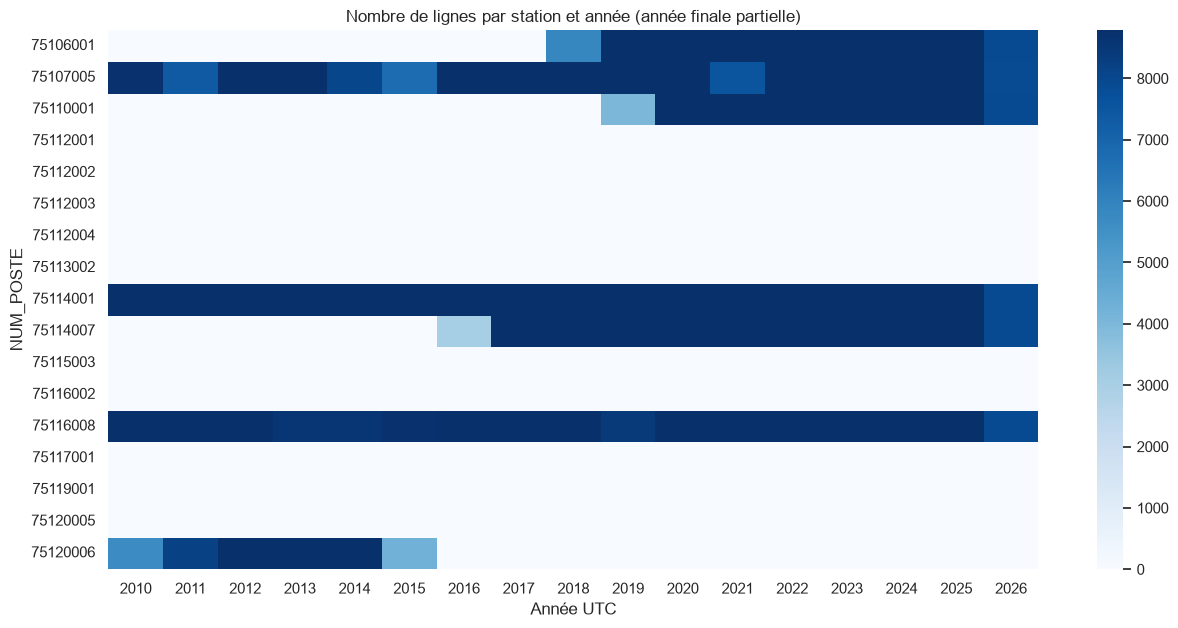

In [5]:
coverage = station_coverage(meteo)
display(coverage)
display(meteo[["NUM_POSTE", "NOM_USUEL", "LAT", "LON", "ALTI"]]
        .drop_duplicates().sort_values("NUM_POSTE"))
annual_rows = pd.crosstab(meteo.NUM_POSTE, meteo.date_utc.dt.year)
plt.figure(figsize=(15, 7))
sns.heatmap(annual_rows, cmap="Blues")
plt.title("Nombre de lignes par station et année (année finale partielle)")
plt.xlabel("Année UTC")
plt.show()


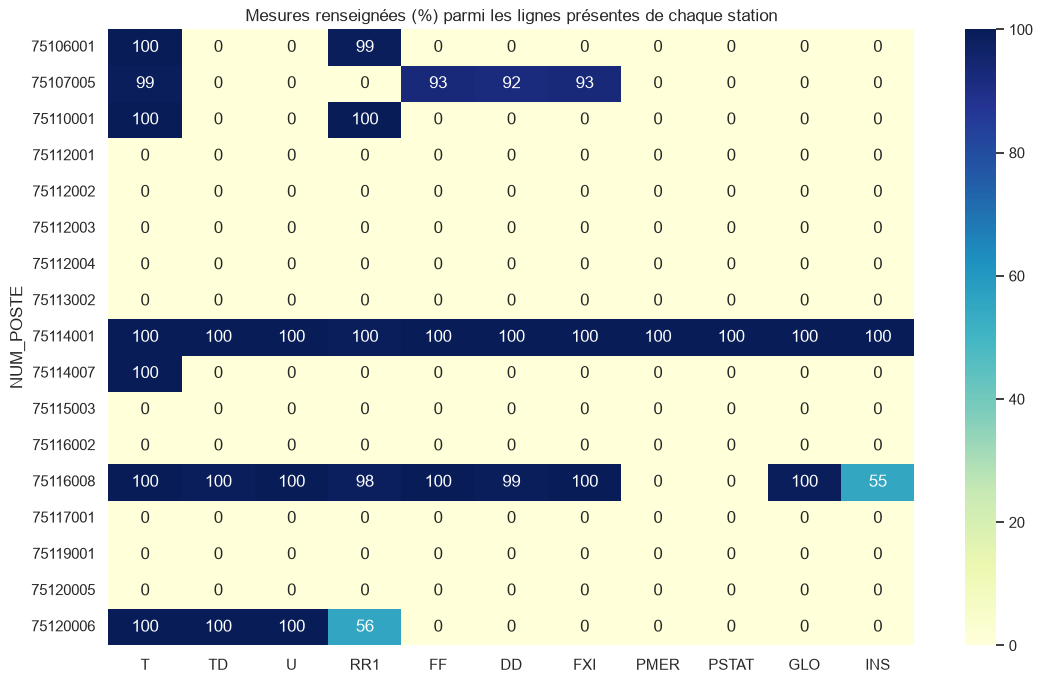

In [6]:
availability = meteo.groupby("NUM_POSTE")[VARIABLES].count().div(
    meteo.groupby("NUM_POSTE").size(), axis=0
) * 100
plt.figure(figsize=(13, 8))
sns.heatmap(availability, vmin=0, vmax=100, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Mesures renseignées (%) parmi les lignes présentes de chaque station")
plt.show()


## 4. Intégrité et codes qualité

La clé attendue est `(NUM_POSTE, date_utc)`. Les doublons sont affichés pour examen, conservés à ce stade. Une date impossible reste signalée par `NaT`.

Les codes qualité ne sont pas une échelle numérique ordonnée : `0` = protégée, `1` = validée, `2` = douteuse en cours de vérification, `9` = filtrée par les premiers contrôles. Un code absent ou non documenté reste à examiner ; `9` ne signifie pas « valeur manquante ».


In [7]:
invalid_dates = meteo.date_utc.isna()
duplicate_keys = meteo.duplicated(["NUM_POSTE", "date_utc"], keep=False)
print("Dates non interprétables :", invalid_dates.sum())
print("Lignes impliquées dans des clés dupliquées :", duplicate_keys.sum())
display(meteo.loc[invalid_dates | duplicate_keys,
    ["NUM_POSTE", "AAAAMMJJHH", "date_utc", "fichier_source"]].head(30))
quality_columns = profile.query("famille == 'qualité'").index.tolist()
quality_counts = pd.DataFrame({c: meteo[c].value_counts(dropna=False)
                               for c in quality_columns}).fillna(0).astype(int).T
print("Légende :", QUALITY_LABELS)
with pd.option_context("display.max_rows", None):
    display(quality_counts)


Dates non interprétables : 0
Lignes impliquées dans des clés dupliquées : 0


,NUM_POSTE,AAAAMMJJHH,date_utc,fichier_source


Légende : {0: 'protégée (validation définitive)', 1: 'validée', 2: 'douteuse, en cours de vérification', 9: 'filtrée (contrôles de premier niveau)'}


,0.0,1.0,9.0,NaN
QRR1,3,464894,36,247629
QDRR1,0,18833,136864,556865
QFF,0,429925,219,282418
QDD,0,428424,27,284111
QFXY,0,354441,29,358092
QDXY,0,354431,27,358104
QHXY,0,2218,352199,358145
QFXI,3,429917,30,282612
QDXI,1,428650,27,283884
QHXI,0,2306,426890,283366


In [8]:
quality_summary = []
for variable in VARIABLES:
    q = meteo["Q" + variable]
    present = meteo[variable].notna()
    quality_summary.append({
        "variable": variable, "mesures": present.sum(),
        "qualité_0_1": (present & q.isin([0, 1])).sum(),
        "qualité_9": (present & q.eq(9)).sum(),
        "qualité_2": (present & q.eq(2)).sum(),
        "mesure_sans_code": (present & q.isna()).sum(),
        "code_sans_mesure": (~present & q.notna()).sum(),
        "code_inconnu": (q.notna() & ~q.isin(QUALITY_LABELS)).sum(),
    })
display(pd.DataFrame(quality_summary).set_index("variable"))


,mesures,qualité_0_1,qualité_9,qualité_2,mesure_sans_code,code_sans_mesure,code_inconnu
variable,,,,,,,
T,711129,696278,14851,0,0,342,0
TD,339202,218571,120631,0,0,0,0
U,339452,335942,3510,0,0,3,0
RR1,456458,456422,36,0,0,8475,0
FF,427951,427732,219,0,0,2193,0
DD,425691,425664,27,0,0,2760,0
FXI,427668,427638,30,0,0,2282,0
PMER,147795,147781,14,0,0,22,0
PSTAT,147618,147609,9,0,0,0,0


## 5. Exploration d'une station

Choisir une station permet d'éviter de mélanger les sites et leurs conditions de mesure. Paris-Montsouris est sélectionnée par défaut pour l'exploration, sans décision définitive sur la station à utiliser pour la modélisation.


In [9]:
STATION = "75114001"  # PARIS-MONTSOURIS ; modifier avec un identifiant du tableau
station = meteo.loc[meteo.NUM_POSTE.eq(STATION)].sort_values("date_utc").copy()
assert not station.empty, "Station absente des fichiers"
print(station.NOM_USUEL.iloc[0], len(station), "lignes")
display(station[VARIABLES].describe(percentiles=[.01, .5, .99]).T)

# Taux calculé sur toutes les heures de chaque année couverte, bornes partielles comprises.
valid = station.dropna(subset=["date_utc"])
assert not valid.date_utc.duplicated().any(), "Examiner les doublons avant réindexation"
hourly = valid.set_index("date_utc")[VARIABLES].reindex(pd.date_range(
    valid.date_utc.min(), valid.date_utc.max(), freq="h", name="date_utc"))
annual_availability = hourly.notna().groupby(hourly.index.year).mean() * 100
display(annual_availability.round(1))


PARIS-MONTSOURIS 148181 lignes


,count,mean,std,min,1%,50%,99%,max
T,148179.0,13.248202,7.117881,-8.3,-1.400,12.8,30.6,41.7
TD,148134.0,7.395590,5.488479,-20.6,-6.268,7.7,17.9,23.3
U,148136.0,70.439380,17.071303,15.0,29.000,73.0,96.0,100.0
RR1,147460.0,0.073805,0.501164,0.0,0.000,0.0,1.8,49.2
FF,147858.0,2.991040,1.396217,0.0,0.600,2.8,7.0,13.4
DD,147833.0,188.755961,101.783480,0.0,10.000,200.0,360.0,360.0
FXI,147833.0,7.339396,3.310601,0.0,1.900,6.9,17.0,33.8
PMER,147795.0,1016.816499,9.219013,969.8,990.900,1017.4,1037.1,1047.8
PSTAT,147618.0,1007.478091,9.106699,960.7,981.700,1008.1,1027.2,1037.8
GLO,147745.0,48.905100,78.255740,0.0,0.000,0.0,301.0,359.0


,T,TD,U,RR1,FF,DD,FXI,PMER,PSTAT,GLO,INS
date_utc,,,,,,,,,,,
2010,100.0,100.0,100.0,99.9,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2011,100.0,100.0,100.0,99.9,100.0,100.0,99.9,100.0,100.0,100.0,100.0
2012,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2013,100.0,100.0,100.0,97.7,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2014,100.0,100.0,100.0,97.3,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2015,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2016,100.0,99.8,99.8,99.2,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2017,100.0,99.7,99.7,99.8,96.4,96.4,96.4,100.0,100.0,95.2,95.2
2018,100.0,100.0,100.0,99.7,100.0,100.0,100.0,100.0,100.0,100.0,100.0


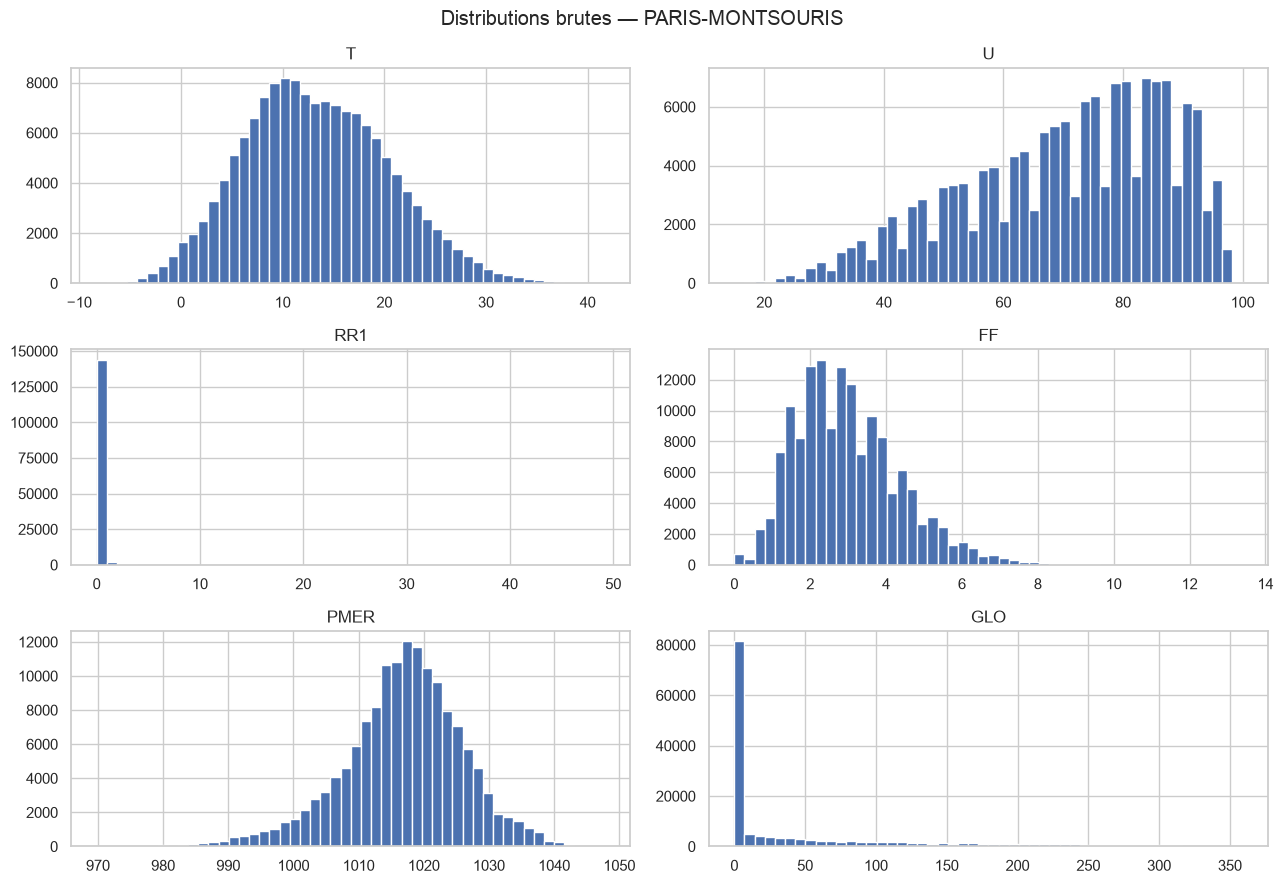

humidité_hors_0_100     0
pluie_négative          0
vent_négatif            0
direction_hors_0_360    0
TN_supérieur_TX         0
rosée_supérieure_T      0
Name: lignes_à_examiner, dtype: int64

,date_utc,T,QT,TD,QTD,U,QU,RR1,QRR1,TN,TX


In [10]:
station[["T", "U", "RR1", "FF", "PMER", "GLO"]].hist(bins=50, figsize=(13, 9))
plt.suptitle(f"Distributions brutes — {station.NOM_USUEL.iloc[0]}")
plt.tight_layout()
plt.show()

# Alertes indicatives : examiner les lignes, ne pas supprimer automatiquement.
checks = pd.DataFrame({
    "humidité_hors_0_100": station.U.notna() & ~station.U.between(0, 100),
    "pluie_négative": station.RR1.lt(0),
    "vent_négatif": station.FF.lt(0),
    "direction_hors_0_360": station.DD.notna() & ~station.DD.between(0, 360),
    "TN_supérieur_TX": station.TN.gt(station.TX),
    "rosée_supérieure_T": station.TD.gt(station["T"] + 0.2),
})
display(checks.sum().rename("lignes_à_examiner"))
display(station.loc[checks.any(axis=1),
    ["date_utc", "T", "QT", "TD", "QTD", "U", "QU", "RR1", "QRR1", "TN", "TX"]].head(20))


## 6. Évolution et saisonnalité

Les moyennes mensuelles résument les observations disponibles ; les mois ayant moins de 90 % d'heures renseignées sur l'intervalle étudié sont masqués. Ce seuil est exploratoire. Pour la pluie, on utilise un cumul, avec `min_count=1` pour éviter de transformer un mois entièrement vide en zéro. Les mois aux bornes des fichiers peuvent rester partiels.

La direction du vent est circulaire : ne pas lui appliquer de moyenne arithmétique (359° et 1° sont proches).


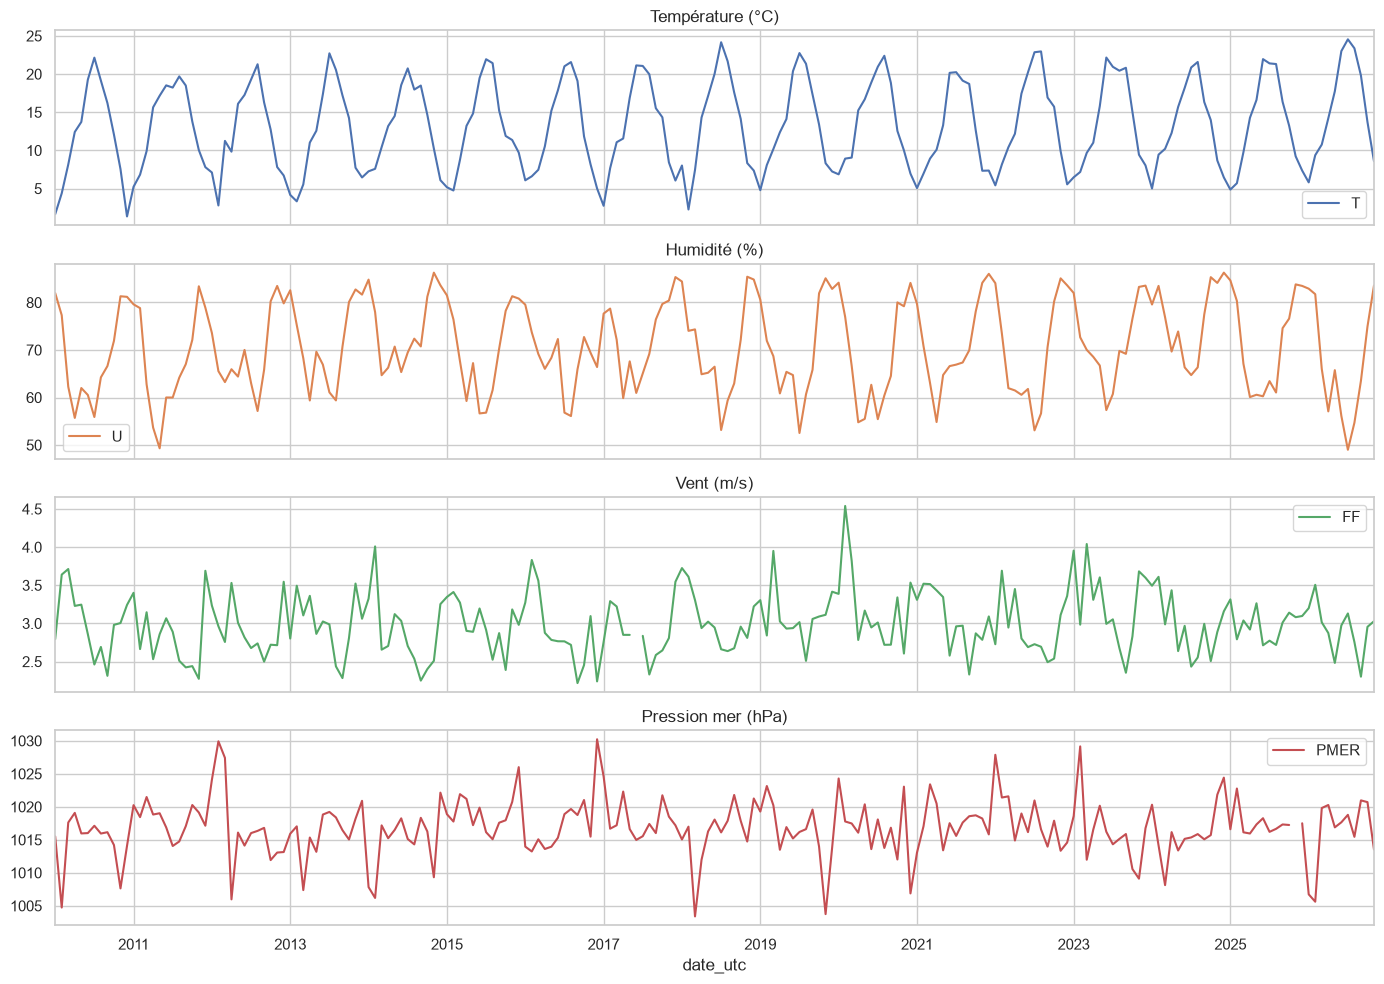

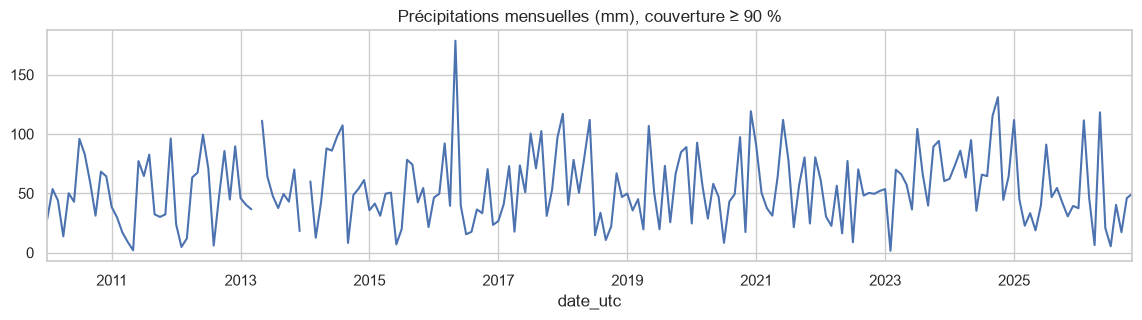

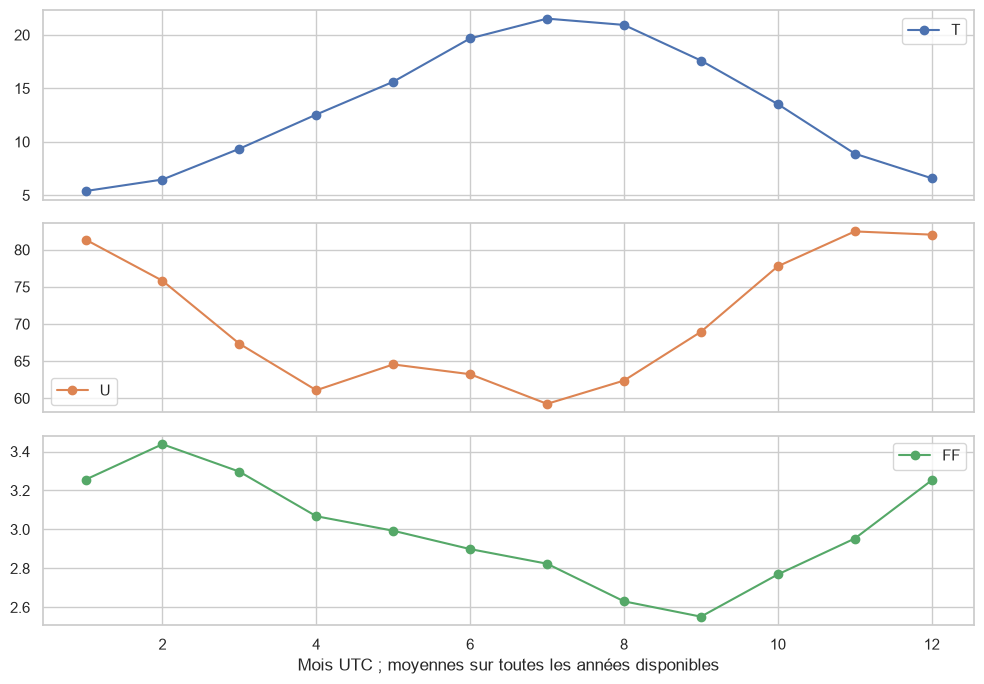

In [11]:
monthly_coverage = hourly.notna().resample("MS").mean()
monthly_mean = hourly[["T", "U", "FF", "PMER"]].resample("MS").mean()
monthly_mean = monthly_mean.where(monthly_coverage[monthly_mean.columns] >= .9)
monthly_mean.plot(subplots=True, figsize=(14, 10), title=[
    "Température (°C)", "Humidité (%)", "Vent (m/s)", "Pression mer (hPa)"])
plt.tight_layout()
plt.show()
monthly_rain = hourly.RR1.resample("MS").sum(min_count=1).where(monthly_coverage.RR1 >= .9)
monthly_rain.plot(figsize=(14, 3), title="Précipitations mensuelles (mm), couverture ≥ 90 %")
plt.show()

seasonality = station.groupby(station.date_utc.dt.month)[["T", "U", "FF"]].mean()
seasonality.plot(subplots=True, figsize=(10, 7), marker="o")
plt.xlabel("Mois UTC ; moyennes sur toutes les années disponibles")
plt.tight_layout()
plt.show()


## 7. Effet d'une politique qualité et prochaines étapes

L'exemple ci-dessous compare les températures brutes à celles portant les codes `0` ou `1`. Il ne constitue pas une règle générale : conserver `9` peut être pertinent selon les paramètres et l'usage. La politique retenue devra être explicite et évaluée par station et par période.


In [12]:
validated_t = station["T"].where(station.QT.isin([0, 1]))
display(pd.DataFrame({"T_brute": station["T"], "T_codes_0_1": validated_t}).describe())
print("Mesures T exclues par cette politique :", station["T"].count() - validated_t.count())


,T_brute,T_codes_0_1
count,148179.000000,148170.000000
mean,13.248202,13.248917
std,7.117881,7.117503
min,-8.300000,-8.300000
25%,8.100000,8.100000
50%,12.800000,12.800000
75%,18.100000,18.100000
max,41.700000,41.700000


Mesures T exclues par cette politique : 9


À décider après lecture des résultats :

- Choisir la station et la période selon la disponibilité des variables utiles et la représentativité géographique.
- Définir le traitement des codes qualité, des doublons et des interruptions ; ne pas remplacer une absence de pluie par un zéro sans justification.
- Vérifier le fuseau et la convention d'horodatage de Geod'air avant toute jointure. Garder une clé UTC ; pour une vue locale, utiliser `date_utc.dt.tz_convert("Europe/Paris")`.
- Distinguer observations météo et prévisions : ces fichiers contiennent des observations. Dans une expérience de prédiction de pollution, vérifier que les variables météo auraient été disponibles à l'instant de prévision pour éviter une fuite d'information.
- Les corrélations et cycles saisonniers éventuels ne suffisent pas à établir un lien causal avec la pollution.

Le notebook reste exploratoire : aucun jeu nettoyé n'est exporté automatiquement.
